# Lung Incomplete_Cases — pan-cancer Hist2Pheno

All **20** Xenium Incomplete_Cases (StarDist-all maps; no TLS / SRI / TNI).
**Top 5** are ranked by matched-cell **L2 macro AUROC** (17 slides have
`*_matched_features.h5ad`). TILD028LA / TILD049MA / VUHD038 have no matched GT
and are last.

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

```bash
bash code/External_val/Lung_Incomplete/demo.sh rank
bash code/External_val/Lung_Incomplete/demo.sh status
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val"))

import unlabeled_external as ue

COHORT = "Lung_Incomplete"
SAVE_FIGURES = False
FIGSIZE = (17.2, 12.5)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

cov = ue.coverage(COHORT)
rank = ue.rank_lung_incomplete(compute=False)
samples = ue.viz_samples(COHORT)
top5 = samples[:5]
rest = samples[5:]
print(f"{COHORT}: {len(cov)} slides; plot order {len(samples)} (top 5 first)")
print("top5", top5)
print("rest", rest)
if rank.empty:
    print("ranks missing — run: bash code/External_val/Lung_Incomplete/demo.sh rank")
else:
    cols = [c for c in (
        "rank_ds", "n_ds", "sample", "n_matched",
        "macro_auc_L1", "macro_auc_L12", "macro_auc_L2", "acc_L2",
    ) if c in rank.columns]
    display(Markdown("### Matched-cell ranks (L2 AUROC). Top 5 are plotted first."))
    display(rank[cols])


Lung_Incomplete: 20 slides; plot order 20 (top 5 first)
top5 ['TILD111LA', 'TILD113LA', 'VUILD105MA1', 'VUILD141MA', 'TILD117MA2']
rest ['VUILD49LA', 'VUILD48LA1', 'VUILD104MA2', 'VUILD58MA', 'TILD299MA', 'TILD315MA', 'VUHD090', 'VUHD049', 'TILD130LA', 'TILD167LA', 'TILD080LA', 'VUILD142MA', 'TILD028LA', 'TILD049MA', 'VUHD038']


### Matched-cell ranks (L2 AUROC). Top 5 are plotted first.

,rank_ds,n_ds,sample,n_matched,macro_auc_L1,macro_auc_L12,macro_auc_L2,acc_L2
0,1.0,17,TILD111LA,10219,0.507891,0.540381,0.549158,0.259517
1,2.0,17,TILD113LA,6039,0.543672,0.556599,0.541161,0.134956
2,3.0,17,VUILD105MA1,10848,0.542688,0.538619,0.528816,0.092552
3,4.0,17,VUILD141MA,13243,0.489956,0.494358,0.508105,0.071887
4,5.0,17,TILD117MA2,5568,0.501731,0.509432,0.505596,0.063937
5,6.0,17,VUILD49LA,8058,0.484357,0.492406,0.504444,0.160834
6,7.0,17,VUILD48LA1,8431,0.494408,0.488684,0.497828,0.182659
7,8.0,17,VUILD104MA2,20924,0.498513,0.503675,0.497083,0.121822
8,9.0,17,VUILD58MA,3218,0.472811,0.483220,0.494757,0.126476
9,10.0,17,TILD299MA,9643,0.509043,0.479832,0.493278,0.088458


## Top 5 by matched L2 AUROC

### TILD111LA  L2 AUROC=0.549  #1/17 Incomplete matched

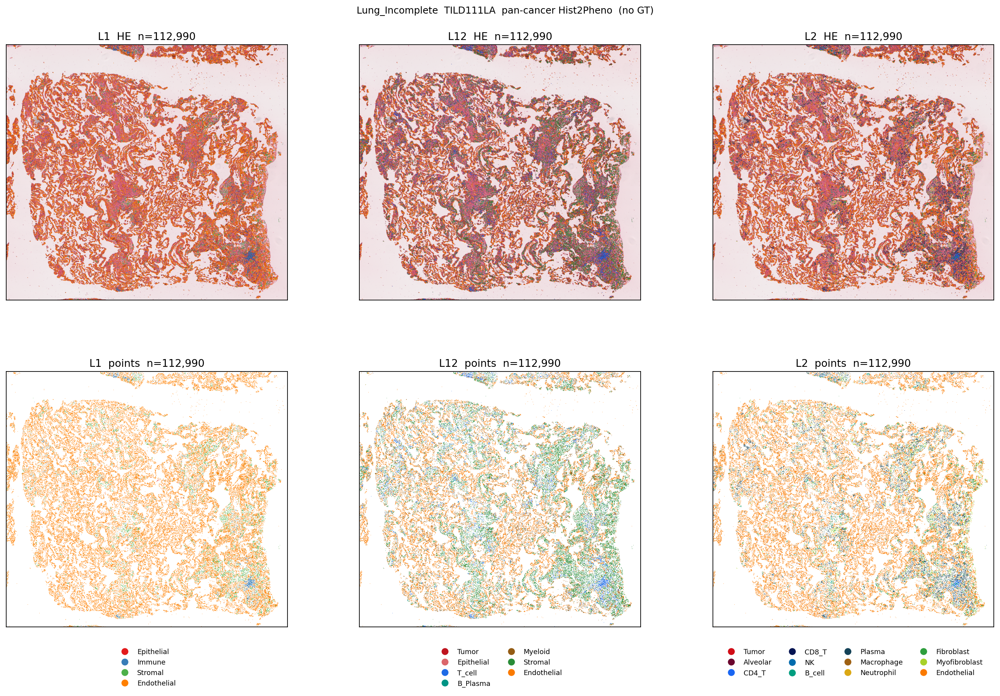

### TILD113LA  L2 AUROC=0.541  #2/17 Incomplete matched

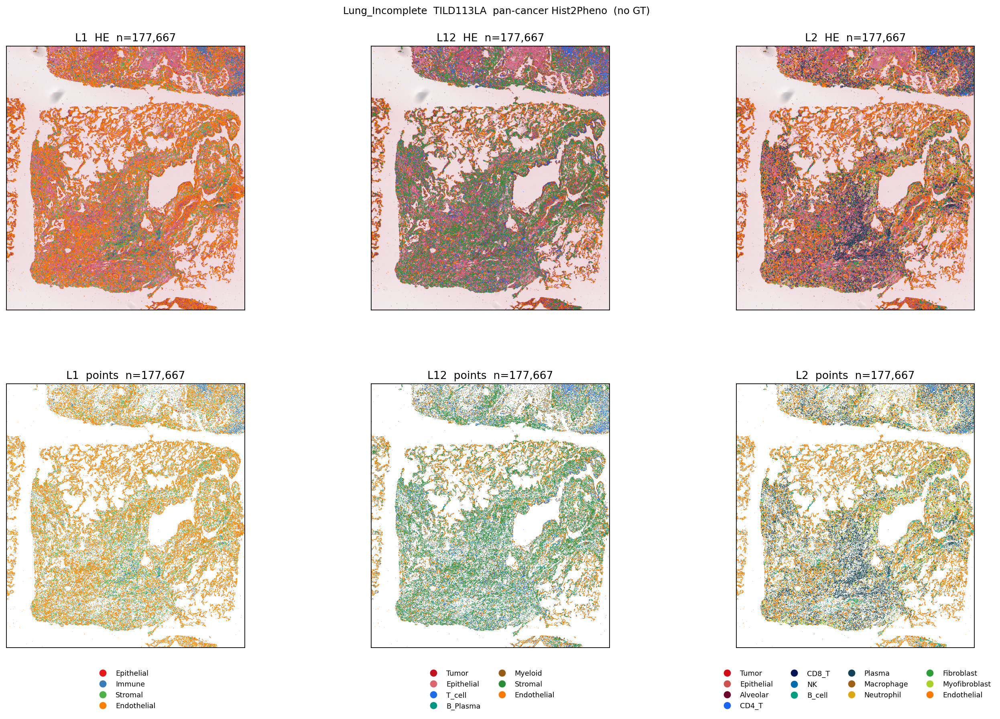

### VUILD105MA1  L2 AUROC=0.529  #3/17 Incomplete matched

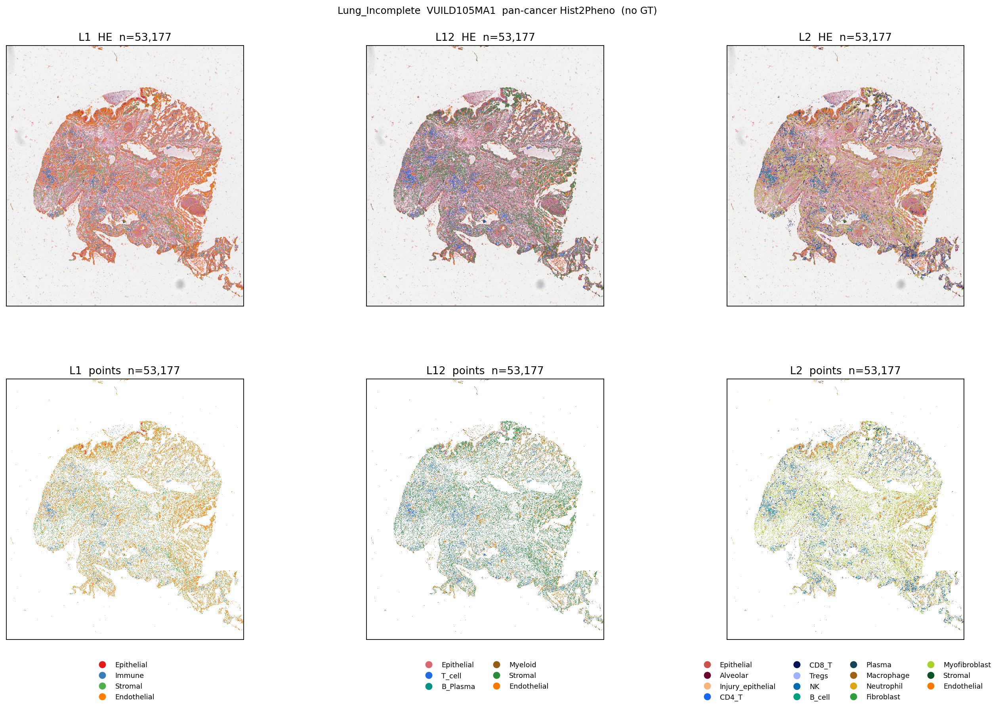

### VUILD141MA  L2 AUROC=0.508  #4/17 Incomplete matched

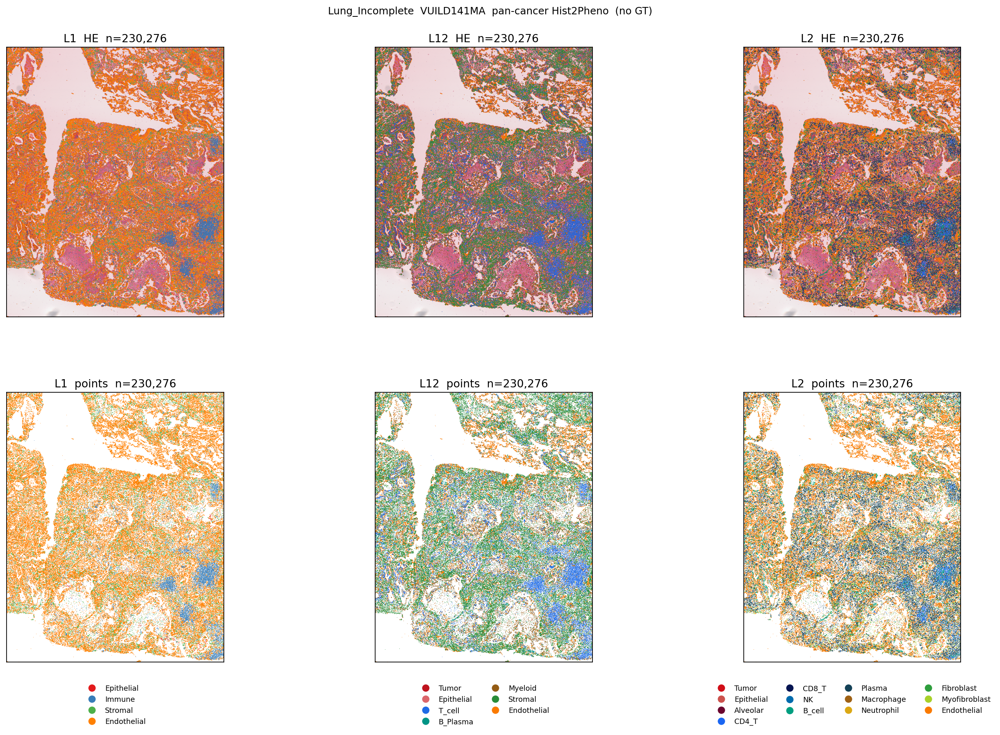

### TILD117MA2  L2 AUROC=0.506  #5/17 Incomplete matched

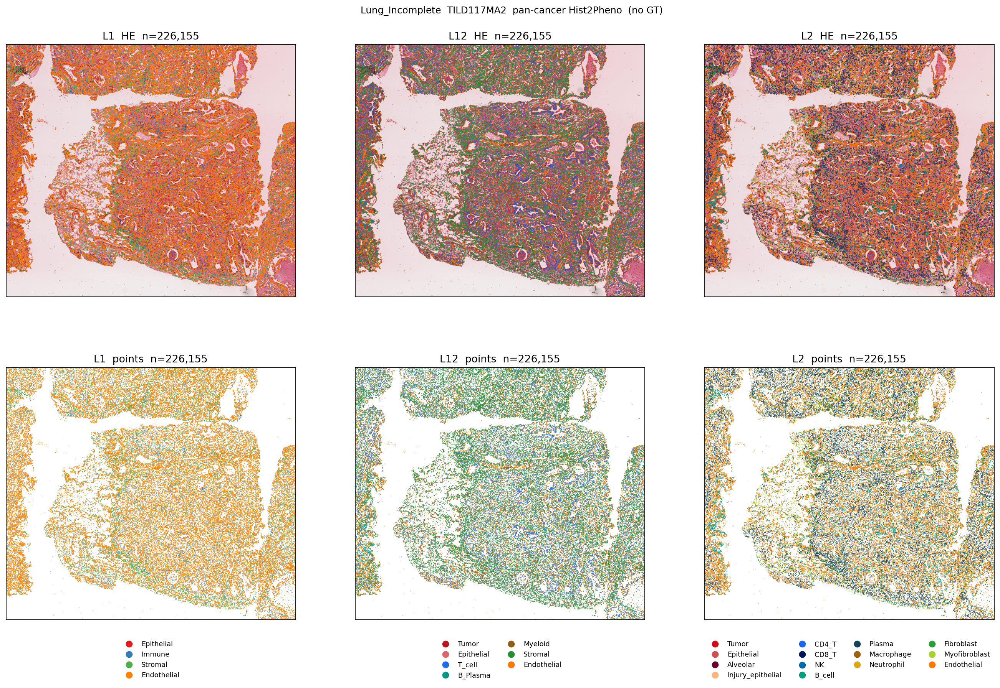

## Remaining Incomplete_Cases

### VUILD49LA  L2 AUROC=0.504  #6/17 Incomplete matched

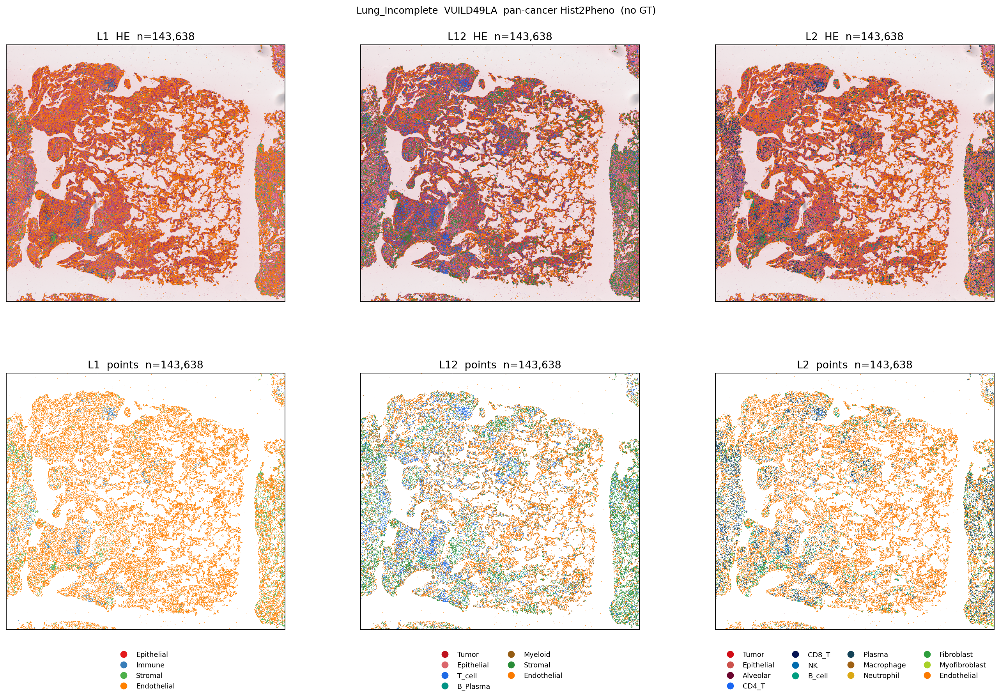

### VUILD48LA1  L2 AUROC=0.498  #7/17 Incomplete matched

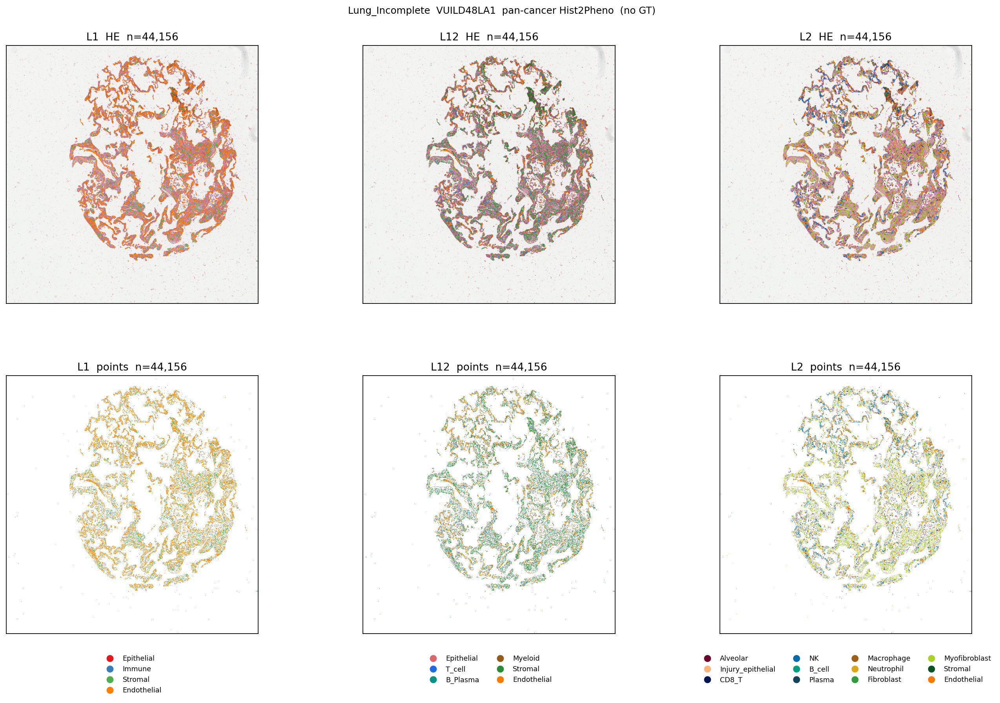

### VUILD104MA2  L2 AUROC=0.497  #8/17 Incomplete matched

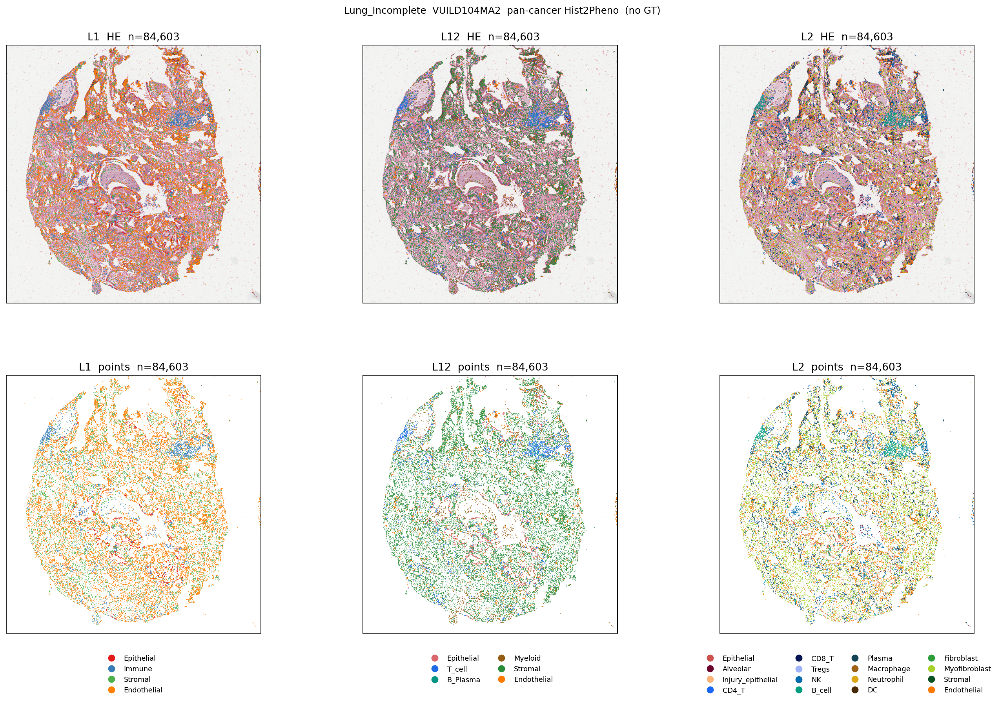

### VUILD58MA  L2 AUROC=0.495  #9/17 Incomplete matched

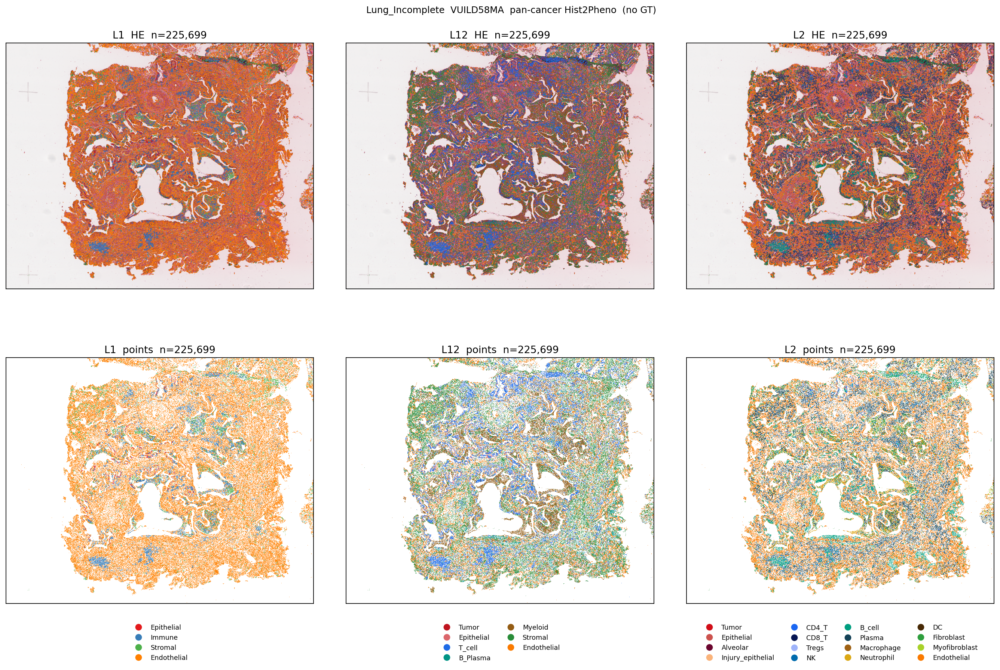

### TILD299MA  L2 AUROC=0.493  #10/17 Incomplete matched

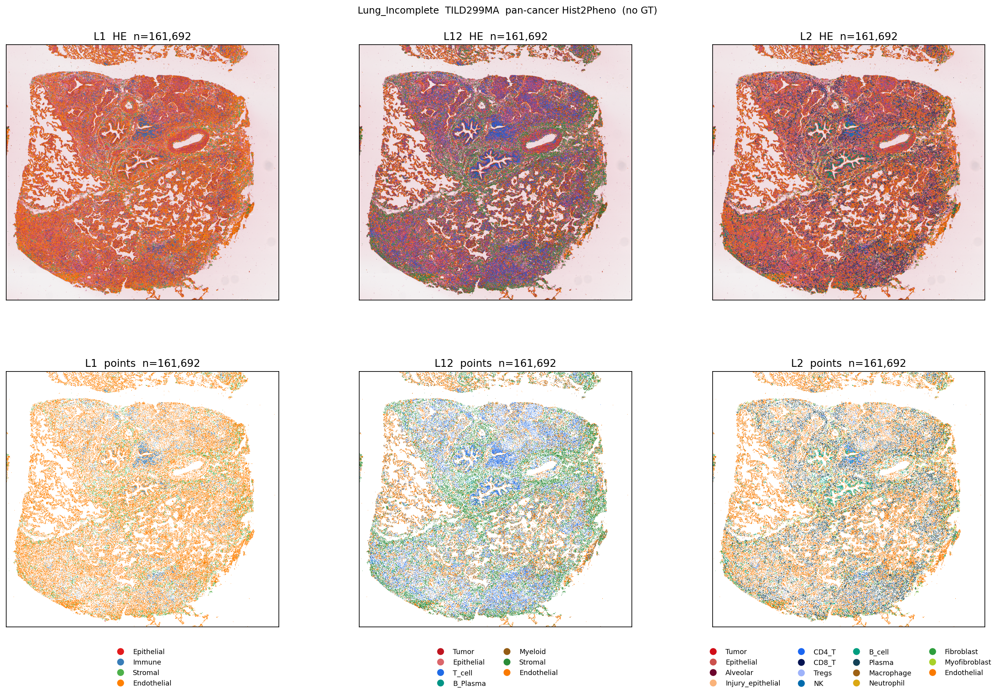

### TILD315MA  L2 AUROC=0.491  #11/17 Incomplete matched

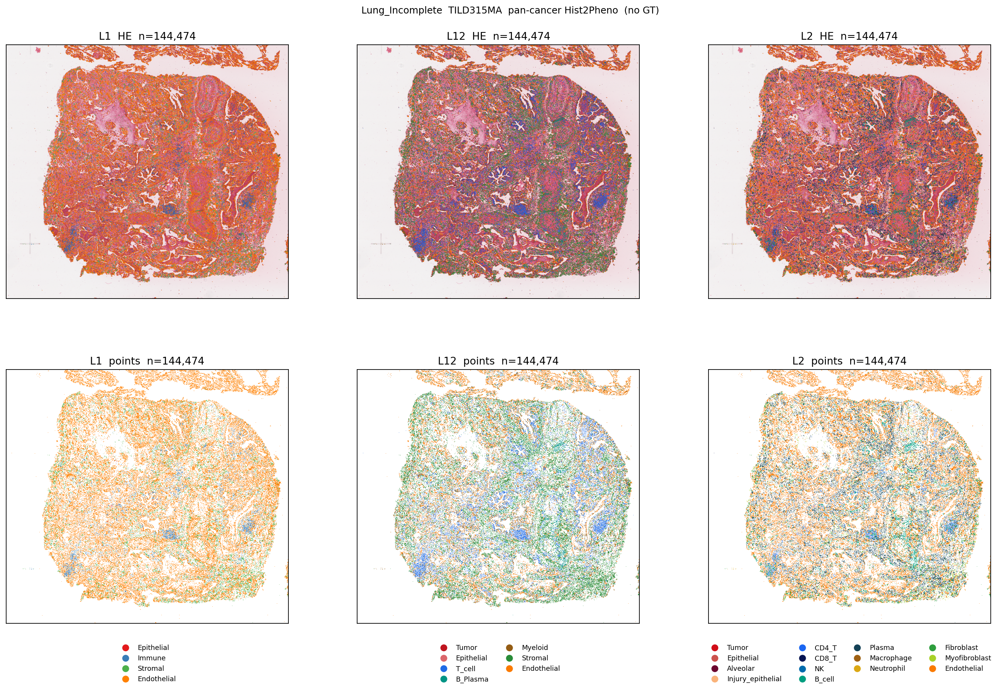

### VUHD090  L2 AUROC=0.489  #12/17 Incomplete matched

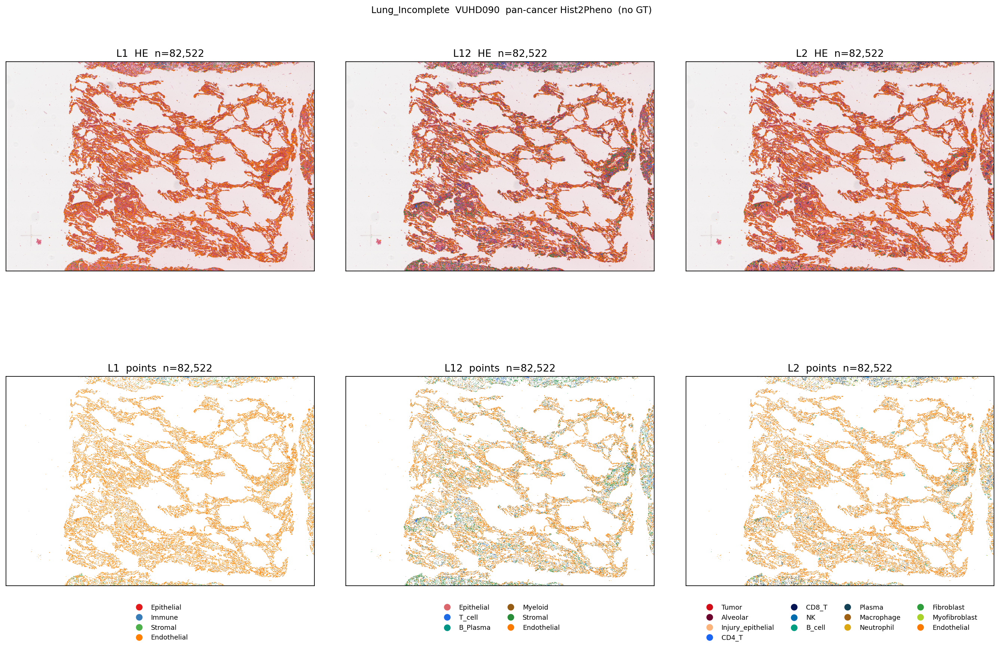

### VUHD049  L2 AUROC=0.482  #13/17 Incomplete matched

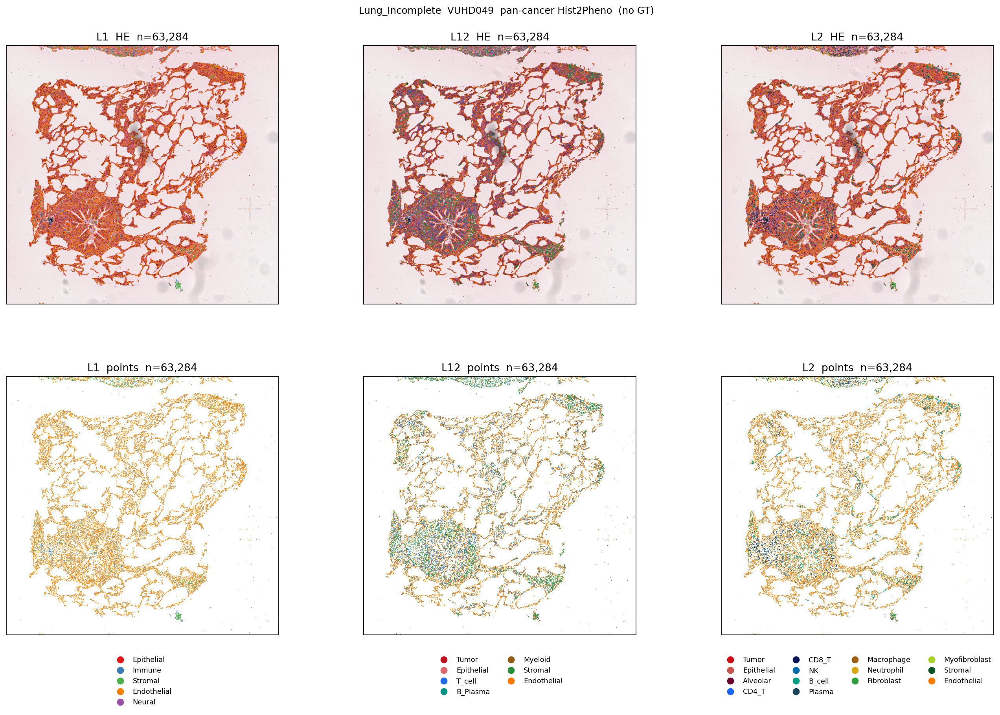

### TILD130LA  L2 AUROC=0.478  #14/17 Incomplete matched

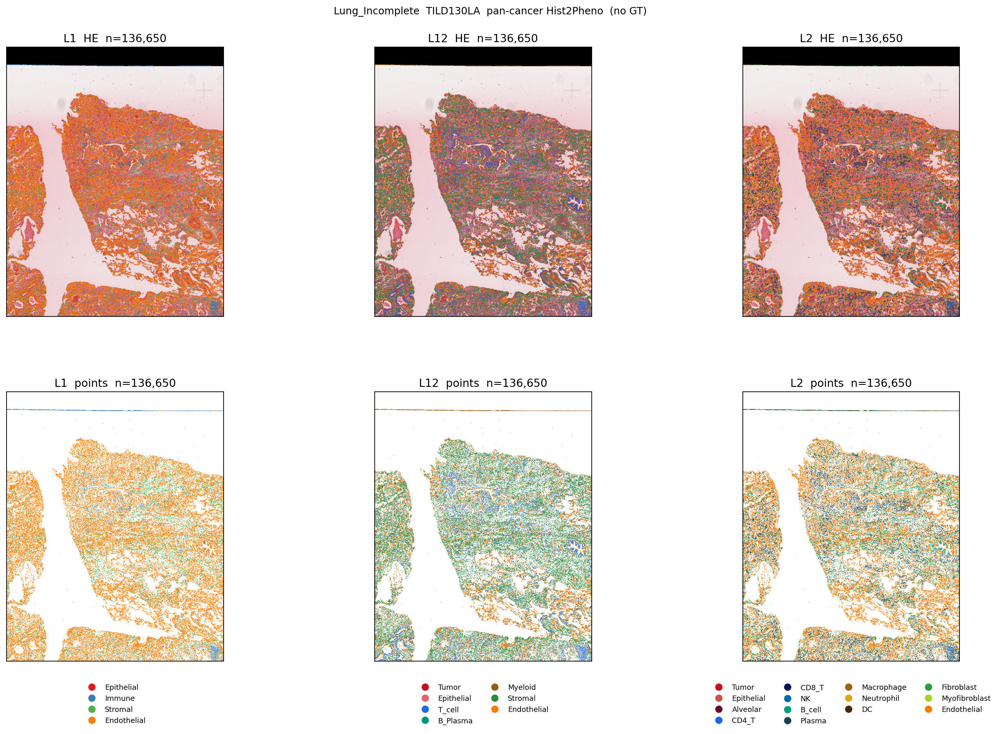

### TILD167LA  L2 AUROC=0.468  #15/17 Incomplete matched

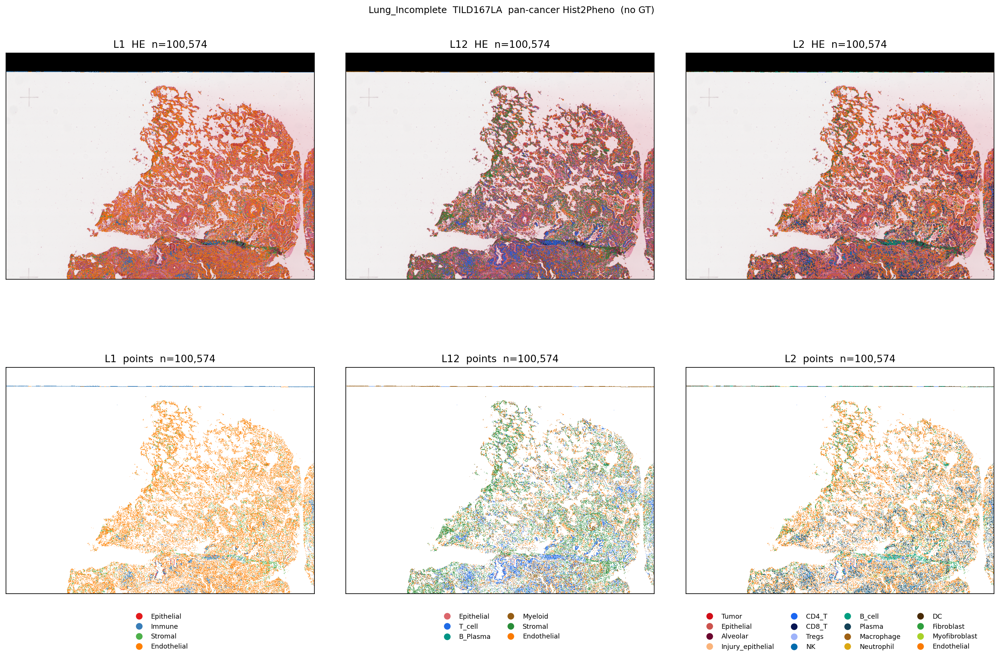

### TILD080LA  L2 AUROC=0.463  #16/17 Incomplete matched

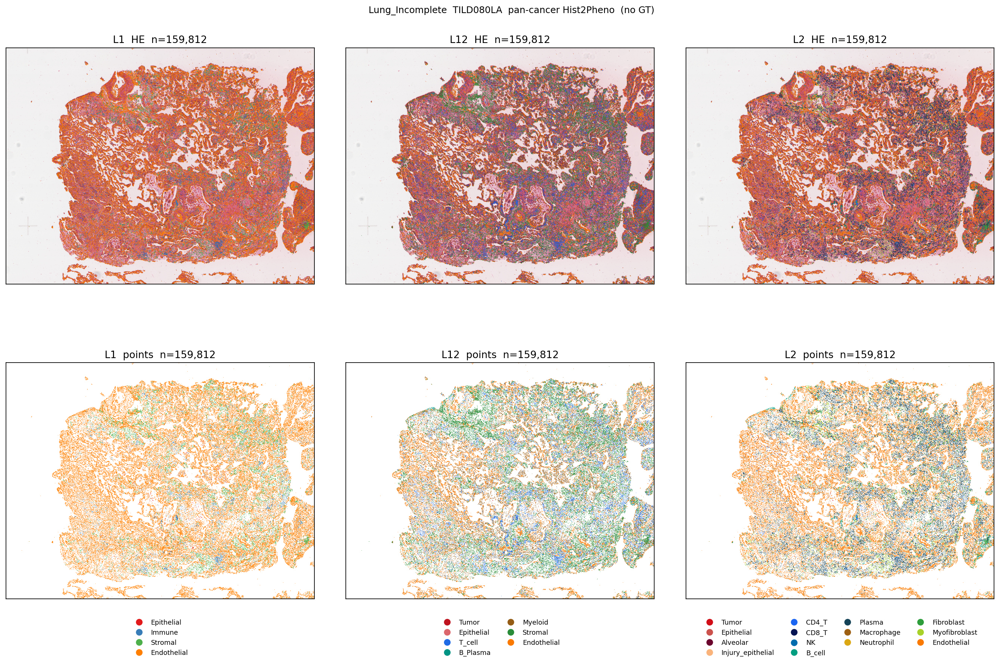

### VUILD142MA  L2 AUROC=0.462  #17/17 Incomplete matched

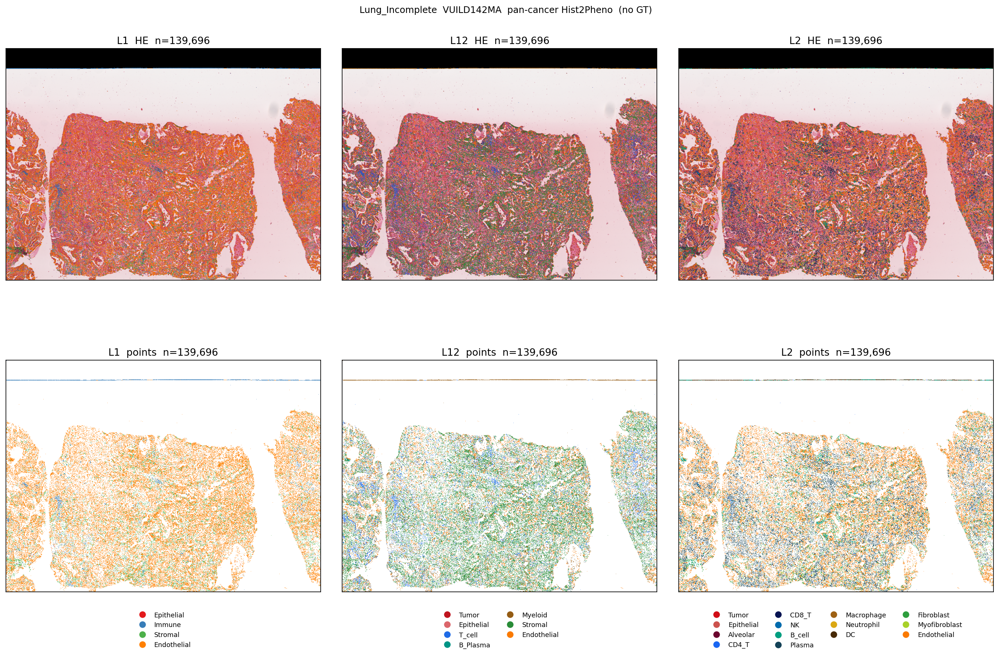

### TILD028LA  (no matched GT)

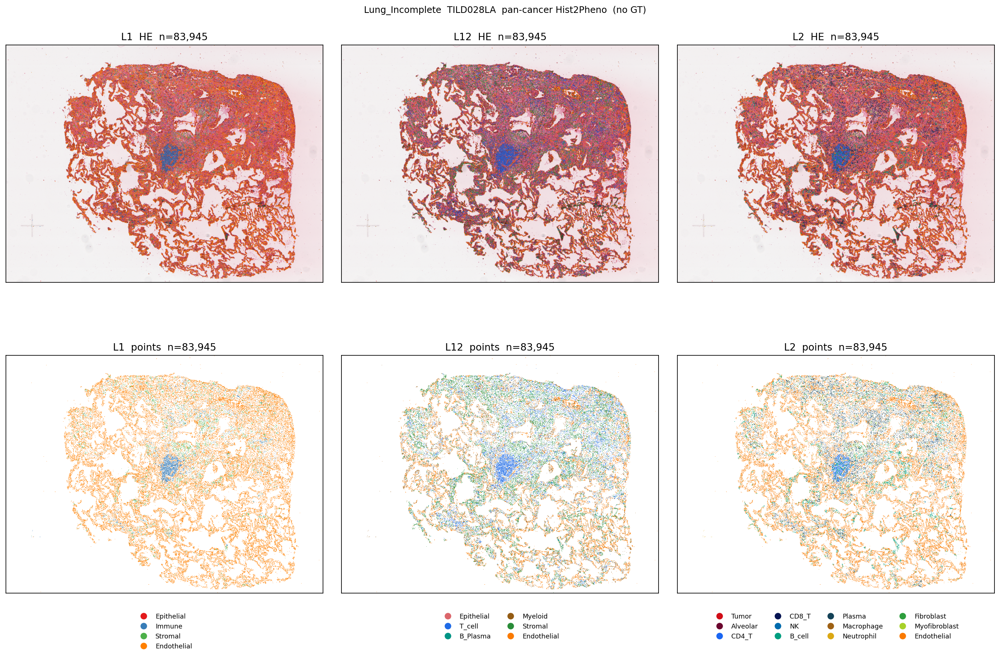

### TILD049MA  (no matched GT)

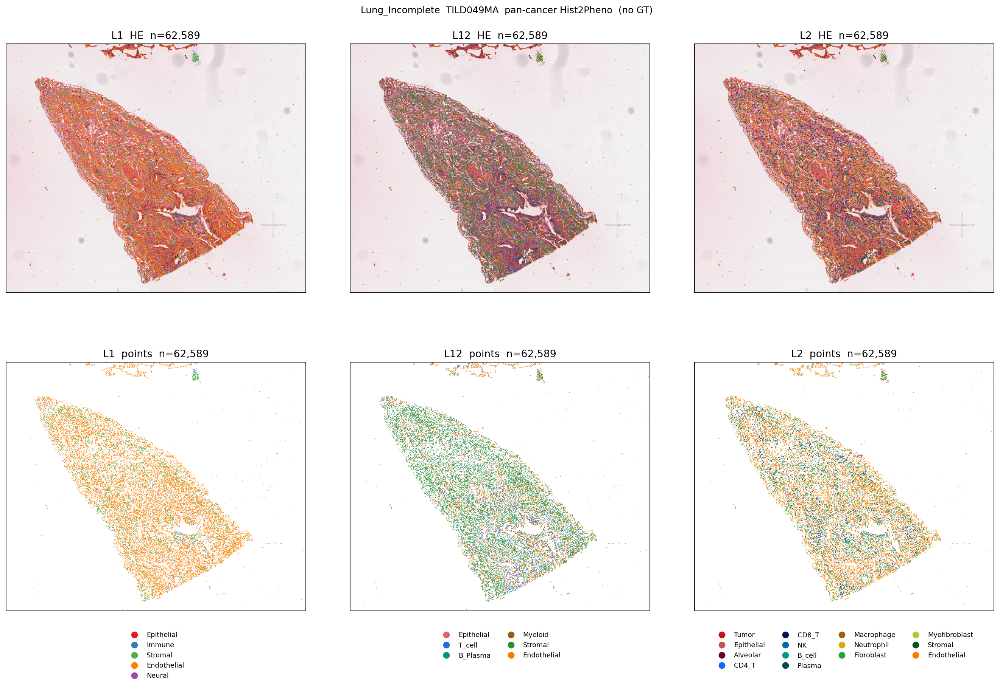

### VUHD038  (no matched GT)

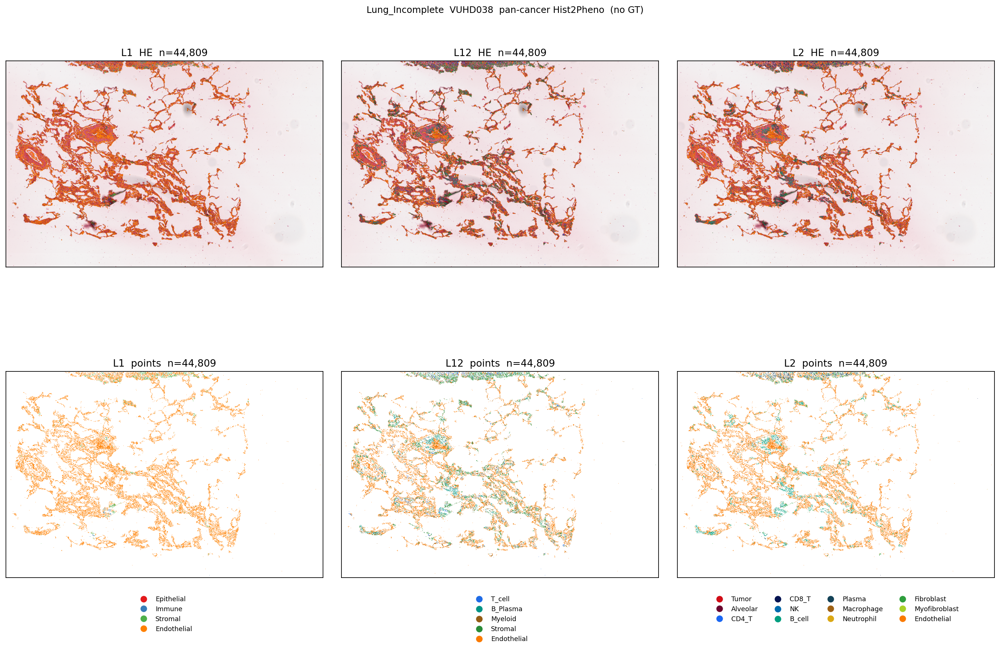

In [2]:
def _rank_title(sample: str) -> str:
    if rank.empty or "sample" not in rank.columns:
        return sample
    hit = rank.loc[rank["sample"].astype(str) == str(sample)]
    if hit.empty:
        return f"{sample}  (no matched GT)"
    rank_ds = hit.iloc[0]["rank_ds"]
    if rank_ds != rank_ds:
        return f"{sample}  (no matched GT)"
    r = hit.iloc[0]
    return (
        f"{sample}  L2 AUROC={float(r.macro_auc_L2):.3f}  "
        f"#{int(r.rank_ds)}/{int(r.n_ds)} Incomplete matched"
    )


def _draw(sample: str) -> None:
    pred = ue.pred_h5ad(ue._cohort(COHORT), sample)
    display(Markdown(f"### {_rank_title(sample)}"))
    if not pred.is_file():
        print("missing pred", sample, "— run demo.sh predict")
        return
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


display(Markdown("## Top 5 by matched L2 AUROC"))
for sample in top5:
    _draw(sample)

display(Markdown("## Remaining Incomplete_Cases"))
for sample in rest:
    _draw(sample)


## Predicted composition — top 5

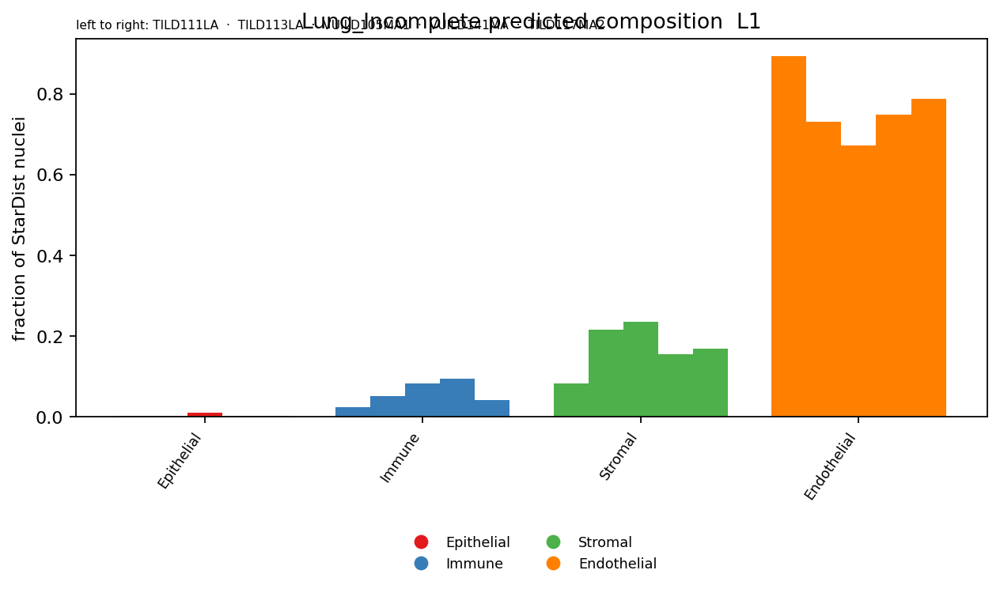

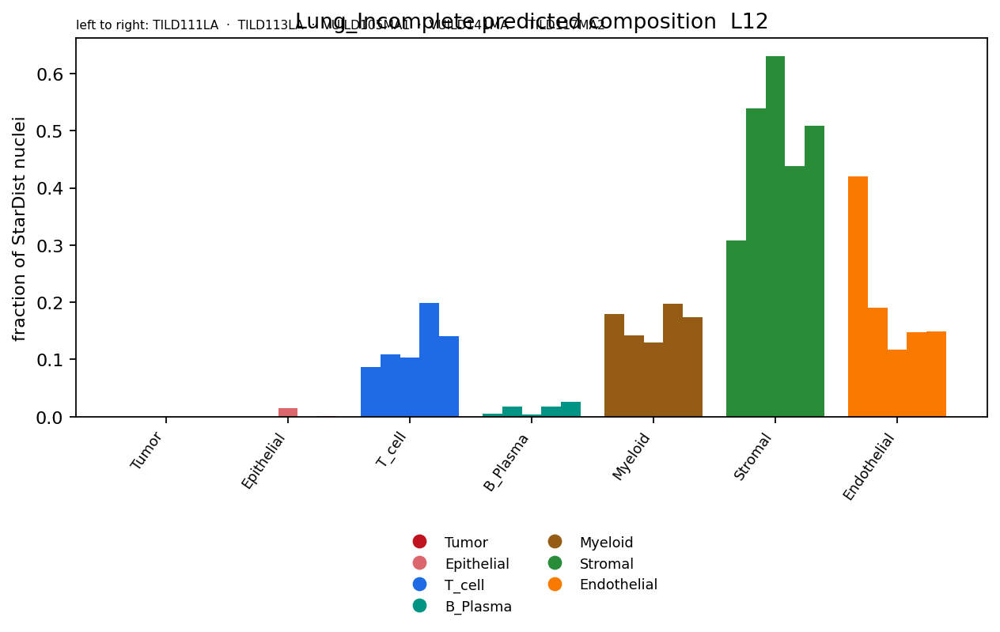

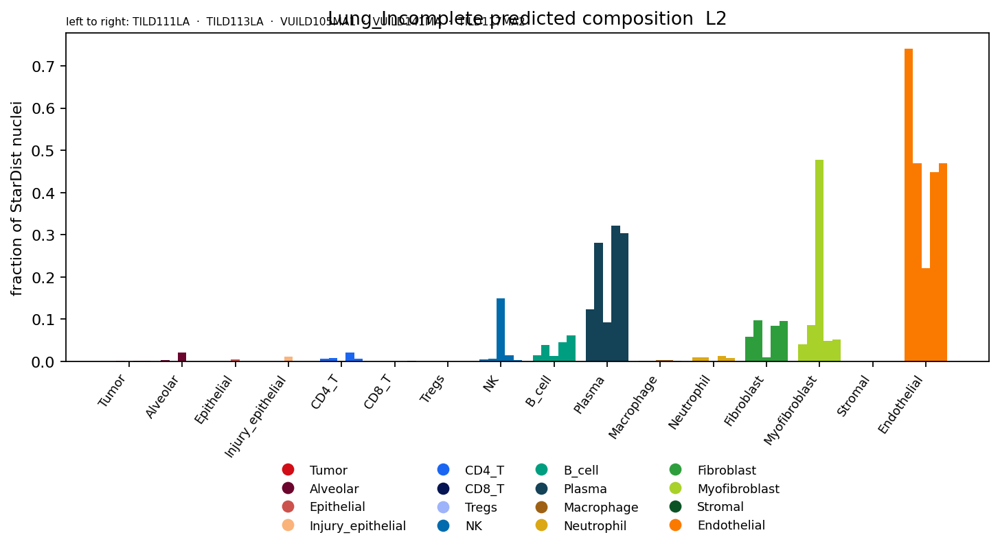

## Predicted composition — remaining

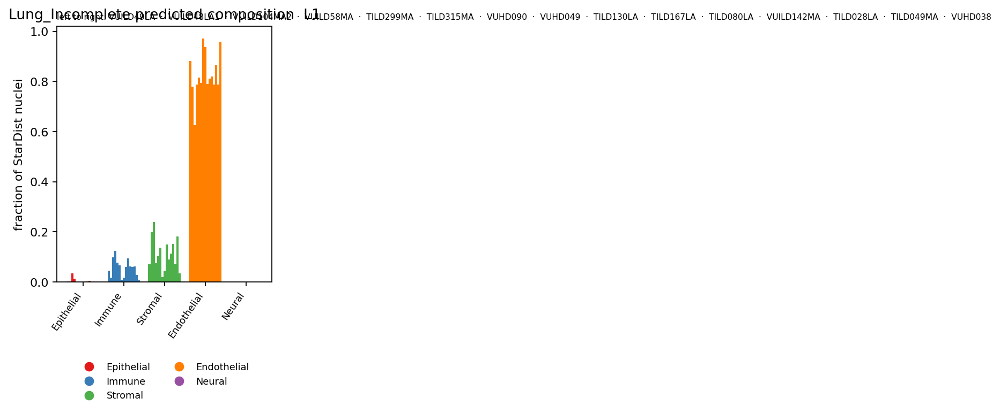

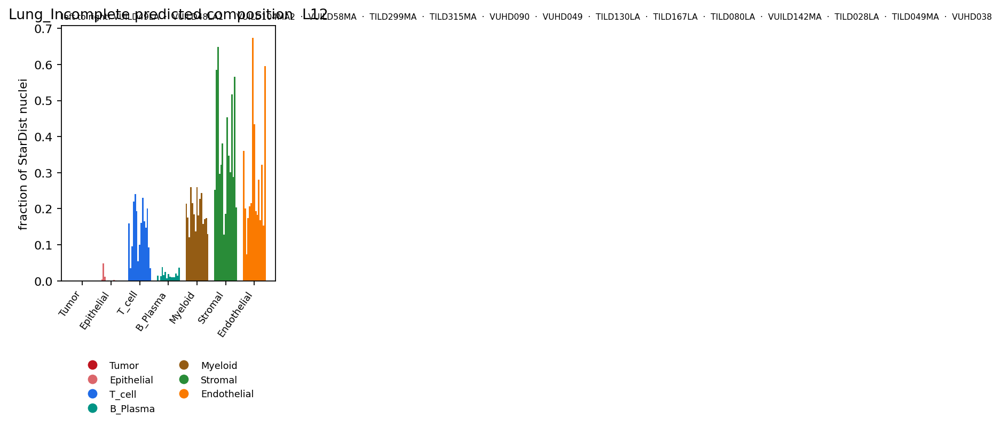

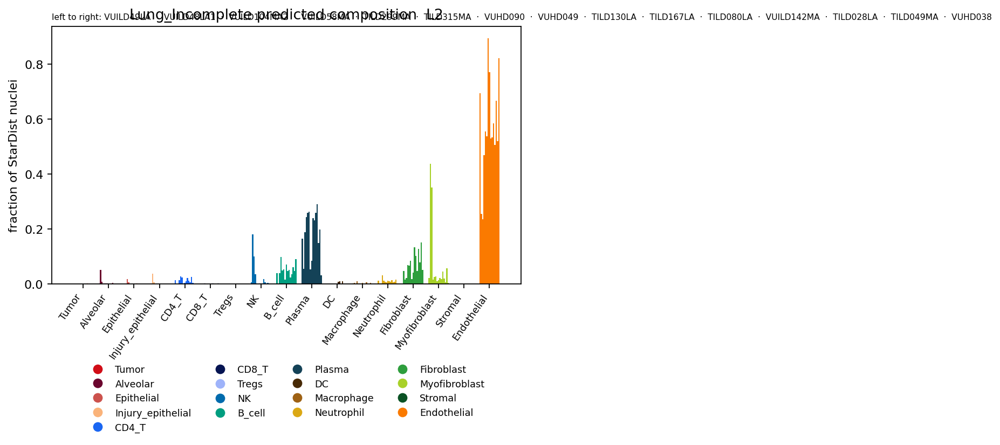

In [3]:
display(Markdown("## Predicted composition — top 5"))
if top5:
    figs = ue.plot_composition(COHORT, top5, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
    for fig in figs:
        display(fig)
        plt.close(fig)

display(Markdown("## Predicted composition — remaining"))
if rest:
    figs = ue.plot_composition(COHORT, rest, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
    for fig in figs:
        display(fig)
        plt.close(fig)
